# Sales Data Analysis Project
## Report, Insights and Overview


## 1. Read, Load and View the Dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

file_path = "Python Project Data.csv"
df = pd.read_csv(file_path)

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

display(df.head())
display(df.tail())
print("Dataset loaded successfully.")

,Date,Branch Location,Product Category,Package Size,Quantity Sold,Unit Price,Total Sales,Channel,Distributor/Customer,Payment Method,Discount/Promotion Applied (%),Returned/Defective Units,Sales Rep / Territory
0,2022-01-31,Sabon Tasha,Coca-Cola,35cl PET,3430,156,535080,Wholesale,Barnawa Traders,Bank Transfer,0,31,F. Kudos
1,2022-12-30,Kakuri,Fanta,35cl PET,3826,148,566248,Wholesale,Sabon Tasha Mart,POS,5,27,F. Kudos
2,2021-05-10,Barnawa,5Alive,Sachet,500,120,60000,Wholesale,Kaduna Drinks Ltd,POS,0,5,A. Martins
3,2022-07-18,Kakuri,Fanta,Glass Bottle,1079,160,172640,Retail,Kaduna Drinks Ltd,POS,5,17,E. Micheal
4,2022-02-04,Kakuri,Eva Water,Sachet,746,65,48490,Wholesale,Central Retailers,POS,0,2,F. Kudos


,Date,Branch Location,Product Category,Package Size,Quantity Sold,Unit Price,Total Sales,Channel,Distributor/Customer,Payment Method,Discount/Promotion Applied (%),Returned/Defective Units,Sales Rep / Territory
1820,2021-06-01,Ungwan Rimi,Fanta,35cl PET,3078,144,443232,Wholesale,Barnawa Traders,Bank Transfer,0,8,C. Okoro
1821,2020-11-18,Kawo,Sprite,33cl Can,1175,198,232650,Retail,Ungwan Rimi Stores,Credit,0,11,A. Martins
1822,2023-03-02,Kakuri,5Alive,Sachet,123,140,17220,Retail,Barnawa Traders,Cash,0,1,A. Martins
1823,2021-04-06,Kakuri,Fanta,33cl Can,1231,205,252355,Retail,Kaduna Drinks Ltd,Cash,5,3,A. Martins
1824,2020-12-27,Kawo,Coca-Cola,35cl PET,1454,125,181750,Retail,Kakuri Wholesale,Credit,5,5,D. Frances


Dataset loaded successfully.


## 2. Dataset size, missing values and duplicates

In [3]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print("Missing values per column:")
display(df.isna().sum().to_frame("Missing values"))
print(f"Total missing cells: {df.isna().sum().sum():,}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Date range: {df['Date'].min():%d %B %Y} to {df['Date'].max():%d %B %Y}")

Rows: 1,825
Columns: 13
Missing values per column:


,Missing values
Date,0
Branch Location,0
Product Category,0
Package Size,0
Quantity Sold,0
Unit Price,0
Total Sales,0
Channel,0
Distributor/Customer,0
Payment Method,0


Total missing cells: 0
Duplicate rows: 0
Date range: 01 January 2019 to 30 December 2023


## 3. Sales, product and package-size analysis

In [3]:
total_sales = df["Total Sales"].sum()
total_quantity = df["Quantity Sold"].sum()
print(f"Total Sales for the period: ₦{total_sales:,.0f}")
print(f"Total Quantity Sold: {total_quantity:,.0f}")

product_sales = df.groupby("Product Category")["Total Sales"].sum().sort_values(ascending=False)
product_qty = df.groupby("Product Category")["Quantity Sold"].sum().sort_values(ascending=False)
size_qty = df.groupby("Package Size")["Quantity Sold"].sum().sort_values(ascending=False)
size_sales = df.groupby("Package Size")["Total Sales"].sum().sort_values()

print(f"Highest sales product: {product_sales.index[0]} (₦{product_sales.iloc[0]:,.0f})")
print(f"Highest quantity product: {product_qty.index[0]} ({product_qty.iloc[0]:,.0f} units)")
print(f"Package size with highest quantity: {size_qty.index[0]} ({size_qty.iloc[0]:,.0f} units)")
print(f"Package size with lowest sales: {size_sales.index[0]} (₦{size_sales.iloc[0]:,.0f})")
print(f"Lowest sales product: {product_sales.index[-1]} (₦{product_sales.iloc[-1]:,.0f})")

display(product_sales.to_frame("Total Sales"))
display(product_qty.to_frame("Quantity Sold"))
display(size_qty.to_frame("Quantity Sold"))
display(size_sales.to_frame("Total Sales"))

Total Sales for the period: ₦404,425,057
Total Quantity Sold: 2,198,410
Highest sales product: Coca-Cola (₦125,164,159)
Highest quantity product: Coca-Cola (670,254 units)
Package size with highest quantity: 33cl Can (480,857 units)
Package size with lowest sales: Sachet (₦8,060,771)
Lowest sales product: 5Alive (₦14,233,909)


,Total Sales
Product Category,
Coca-Cola,125164159
Fanta,96370382
Sprite,80973252
Eva Water,49123310
Schweppes,38560045
5Alive,14233909


,Quantity Sold
Product Category,
Coca-Cola,670254
Fanta,510845
Sprite,440436
Eva Water,336216
Schweppes,183800
5Alive,56859


,Quantity Sold
Package Size,
33cl Can,480857
Glass Bottle,429056
35cl PET,350392
50cl PET,321043
1L PET,257285
75cl PET,153009
Sachet,113664
1.5L PET,93104


,Total Sales
Package Size,
Sachet,8060771
75cl PET,21849530
1.5L PET,21956696
35cl PET,48692324
50cl PET,55918661
Glass Bottle,67302725
1L PET,75421318
33cl Can,105223032


## 4. Branch and Territory Performance

In [4]:
branch_sales = df.groupby("Branch Location")["Total Sales"].sum().sort_values(ascending=False)
rep_sales = df.groupby("Sales Rep / Territory")["Total Sales"].sum().sort_values(ascending=False)
branch_returns = df.groupby("Branch Location")["Returned/Defective Units"].sum().sort_values(ascending=False)

print(f"Highest-sales branch: {branch_sales.index[0]} (₦{branch_sales.iloc[0]:,.0f})")
print(f"Lowest-sales branch: {branch_sales.index[-1]} (₦{branch_sales.iloc[-1]:,.0f})")
print(f"Top Sales Rep/Territory: {rep_sales.index[0]} (₦{rep_sales.iloc[0]:,.0f})")
print(f"Branch with highest returns: {branch_returns.index[0]} ({branch_returns.iloc[0]:,.0f} units)")
display(branch_sales.to_frame("Total Sales"))
display(rep_sales.to_frame("Total Sales"))
display(branch_returns.to_frame("Returned/Defective Units"))

Highest-sales branch: Kaduna Central (₦71,640,835)
Lowest-sales branch: Kakuri (₦46,943,272)
Top Sales Rep/Territory: D. Frances (₦62,445,007)
Branch with highest returns: Kaduna Central (3,309 units)


,Total Sales
Branch Location,
Kaduna Central,71640835
Barnawa,68727892
Zaria Depot,65375397
Ungwan Rimi,53863351
Sabon Tasha,50195332
Kawo,47678978
Kakuri,46943272


,Total Sales
Sales Rep / Territory,
D. Frances,62445007
F. Kudos,60775186
C. Okoro,59602750
A. Martins,59363246
E. Micheal,55132053
G. Natasha,54297177
B. Victory,52809638


,Returned/Defective Units
Branch Location,
Kaduna Central,3309
Barnawa,2996
Zaria Depot,2559
Sabon Tasha,2245
Kawo,2061
Ungwan Rimi,2012
Kakuri,1924


## 5. Sales Channels and Customers

In [5]:
channel_sales = df.groupby("Channel")["Total Sales"].sum().sort_values(ascending=False)
customer_qty = df.groupby("Distributor/Customer")["Quantity Sold"].sum().sort_values(ascending=False)
print(f"Highest-sales channel: {channel_sales.index[0]} (₦{channel_sales.iloc[0]:,.0f})")
print(f"Customer with highest quantity: {customer_qty.index[0]} ({customer_qty.iloc[0]:,.0f} units)")
display(channel_sales.to_frame("Total Sales"))
display(customer_qty.to_frame("Quantity Sold"))

# Annual channel totals and comparison of first and last years
df["Year"] = df["Date"].dt.year
annual_channel_sales = df.groupby(["Year", "Channel"])["Total Sales"].sum().unstack(fill_value=0)
display(annual_channel_sales)
first_year, last_year = annual_channel_sales.index.min(), annual_channel_sales.index.max()
for channel in annual_channel_sales.columns:
    first = annual_channel_sales.loc[first_year, channel]
    last = annual_channel_sales.loc[last_year, channel]
    direction = "increased" if last > first else ("decreased" if last < first else "remained unchanged")
    pct = ((last-first)/first*100) if first else float("nan")
    print(f"{channel}: {direction} from ₦{first:,.0f} ({first_year}) to ₦{last:,.0f} ({last_year}); change {pct:.1f}%.")

Highest-sales channel: Wholesale (₦194,132,768)
Customer with highest quantity: Zaria Beverages (336,457 units)


,Total Sales
Channel,
Wholesale,194132768
Retail,177042267
Modern Trade,33250022


,Quantity Sold
Distributor/Customer,
Zaria Beverages,336457
Kakuri Wholesale,325829
Barnawa Traders,325080
Central Retailers,323027
Ungwan Rimi Stores,303068
Sabon Tasha Mart,294848
Kaduna Drinks Ltd,290101


Channel,Modern Trade,Retail,Wholesale
Year,,,
2019,5566351,28396926,27719451
2020,9335509,30894484,33367482
2021,5003037,40738749,43724862
2022,5541102,37700769,42402958
2023,7804023,39311339,46918015


Modern Trade: increased from ₦5,566,351 (2019) to ₦7,804,023 (2023); change 40.2%.
Retail: increased from ₦28,396,926 (2019) to ₦39,311,339 (2023); change 38.4%.
Wholesale: increased from ₦27,719,451 (2019) to ₦46,918,015 (2023); change 69.3%.


## 6. Visualizations

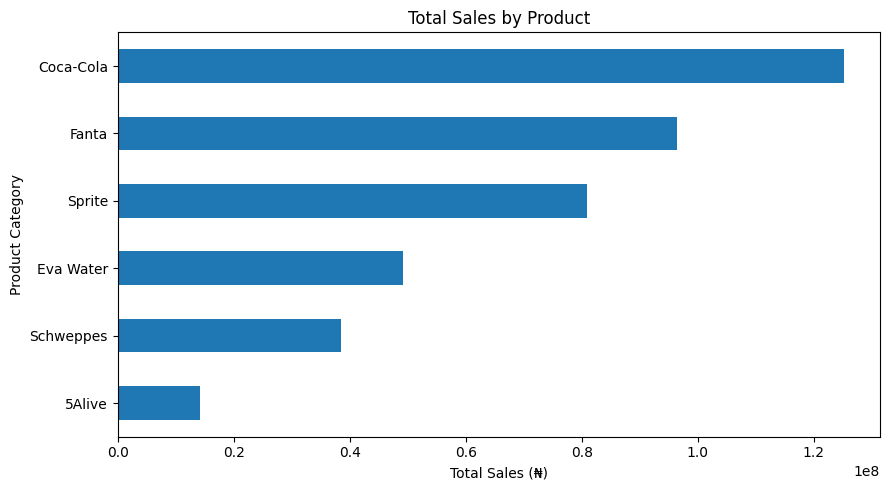

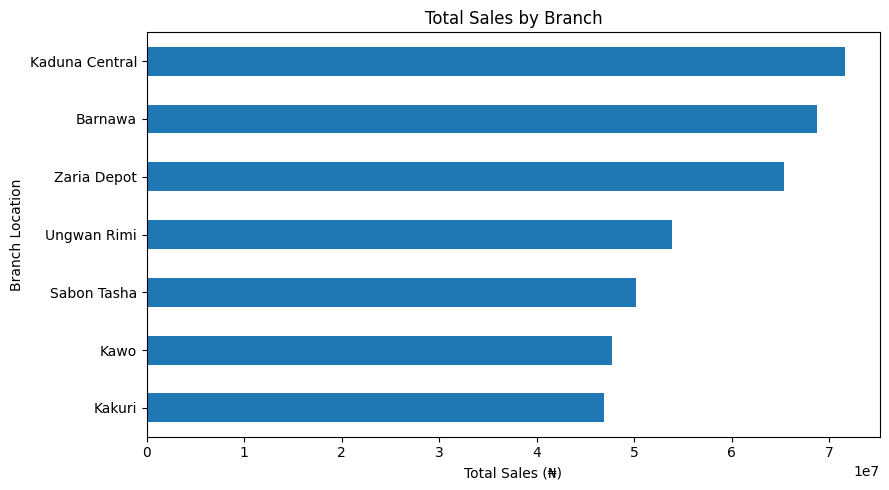

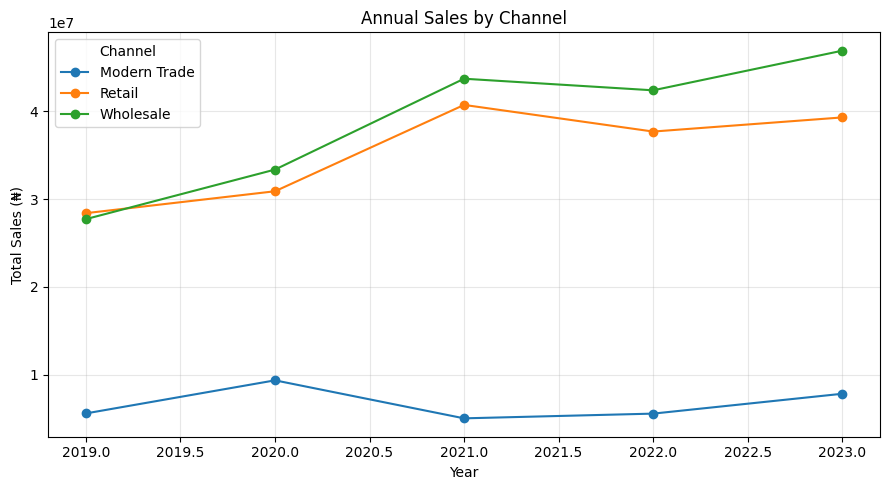

In [6]:
# Product sales
product_sales.sort_values().plot(kind="barh", figsize=(9,5), title="Total Sales by Product")
plt.xlabel("Total Sales (₦)")
plt.tight_layout()
plt.show()

# Branch sales
branch_sales.sort_values().plot(kind="barh", figsize=(9,5), title="Total Sales by Branch")
plt.xlabel("Total Sales (₦)")
plt.tight_layout()
plt.show()

# Annual channel trend
annual_channel_sales.plot(kind="line", marker="o", figsize=(9,5), title="Annual Sales by Channel")
plt.ylabel("Total Sales (₦)")
plt.xlabel("Year")
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()

## 7. Management Report

In [7]:
report = f"""SALES PERFORMANCE REPORT
Period: {df["Date"].min():%d %b %Y} – {df["Date"].max():%d %b %Y}

Dataset contains {len(df):,} records across {df.shape[1]} columns.
Total sales: ₦{total_sales:,.0f}; total quantity sold: {total_quantity:,.0f} units.

Product leader: {product_sales.index[0]} (₦{product_sales.iloc[0]:,.0f}).
Product with lowest sales: {product_sales.index[-1]} (₦{product_sales.iloc[-1]:,.0f}).
Highest-volume product: {product_qty.index[0]} ({product_qty.iloc[0]:,.0f} units).
Highest-volume package: {size_qty.index[0]} ({size_qty.iloc[0]:,.0f} units).
Lowest-sales package: {size_sales.index[0]} (₦{size_sales.iloc[0]:,.0f}).

Branch leader: {branch_sales.index[0]} (₦{branch_sales.iloc[0]:,.0f}); lowest branch: {branch_sales.index[-1]} (₦{branch_sales.iloc[-1]:,.0f}).
Top Sales Rep/Territory: {rep_sales.index[0]} (₦{rep_sales.iloc[0]:,.0f}).
Most returns: {branch_returns.index[0]} ({branch_returns.iloc[0]:,.0f} units).

Channel leader: {channel_sales.index[0]} (₦{channel_sales.iloc[0]:,.0f}).
Top customer by quantity: {customer_qty.index[0]} ({customer_qty.iloc[0]:,.0f} units).
"""
print(report)

SALES PERFORMANCE REPORT
Period: 01 Jan 2019 – 30 Dec 2023

Dataset contains 1,825 records across 14 columns.
Total sales: ₦404,425,057; total quantity sold: 2,198,410 units.

Product leader: Coca-Cola (₦125,164,159).
Product with lowest sales: 5Alive (₦14,233,909).
Highest-volume product: Coca-Cola (670,254 units).
Highest-volume package: 33cl Can (480,857 units).
Lowest-sales package: Sachet (₦8,060,771).

Branch leader: Kaduna Central (₦71,640,835); lowest branch: Kakuri (₦46,943,272).
Top Sales Rep/Territory: D. Frances (₦62,445,007).
Most returns: Kaduna Central (3,309 units).

Channel leader: Wholesale (₦194,132,768).
Top customer by quantity: Zaria Beverages (336,457 units).



## 8. Insight (one paragraph)

In [8]:
insight = (
    f"Across {df['Date'].min():%Y}–{df['Date'].max():%Y}, the business recorded ₦{total_sales:,.0f} "
    f"in sales from {total_quantity:,.0f} units. {product_sales.index[0]} was the strongest product by revenue, "
    f"while {product_qty.index[0]} led product volume; {size_qty.index[0]} was the best-selling package size by quantity. "
    f"{branch_sales.index[0]} generated the highest branch sales, whereas {branch_sales.index[-1]} was lowest. "
    f"{rep_sales.index[0]} led sales representatives/territories. {channel_sales.index[0]} contributed the most revenue, "
    f"and {customer_qty.index[0]} purchased the most units. {branch_returns.index[0]} recorded the highest returned/defective units, "
    "so it may warrant a focused quality and fulfilment review. Channel annual comparisons above show whether each channel grew "
    "between the first and last calendar years represented."
)
print(insight)

Across 2019–2023, the business recorded ₦404,425,057 in sales from 2,198,410 units. Coca-Cola was the strongest product by revenue, while Coca-Cola led product volume; 33cl Can was the best-selling package size by quantity. Kaduna Central generated the highest branch sales, whereas Kakuri was lowest. D. Frances led sales representatives/territories. Wholesale contributed the most revenue, and Zaria Beverages purchased the most units. Kaduna Central recorded the highest returned/defective units, so it may warrant a focused quality and fulfilment review. Channel annual comparisons above show whether each channel grew between the first and last calendar years represented.


## 9. Overview

In [9]:
print("OVERVIEW")
print(f"• Records analyzed: {len(df):,}")
print(f"• Data quality: {df.isna().sum().sum()} missing cells; {df.duplicated().sum()} duplicate rows")
print(f"• Sales: ₦{total_sales:,.0f}")
print(f"• Quantity: {total_quantity:,.0f} units")
print(f"• Date coverage: {df['Date'].min():%Y}–{df['Date'].max():%Y}")
print(f"• Leading product (sales): {product_sales.index[0]}")
print(f"• Leading branch (sales): {branch_sales.index[0]}")
print(f"• Leading channel (sales): {channel_sales.index[0]}")

OVERVIEW
• Records analyzed: 1,825
• Data quality: 0 missing cells; 0 duplicate rows
• Sales: ₦404,425,057
• Quantity: 2,198,410 units
• Date coverage: 2019–2023
• Leading product (sales): Coca-Cola
• Leading branch (sales): Kaduna Central
• Leading channel (sales): Wholesale


## Conclusion
The analysis identifies the leading products, package sizes, branches, sales territories, channels and customers, and highlights returns for operational follow-up. Use the tables and charts above to support decisions on inventory, distribution, channel strategy and quality control.